<a href="https://colab.research.google.com/github/ReetomGogoi/GhostVision-AI/blob/feature%2Fthermal/GhostVision_Thermal_Nikhil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import os
import shutil

print("Colab is ready!")
print("Available disk space:", round(shutil.disk_usage("/content").free / 1e9, 2), "GB")
print("GPU check:")
!nvidia-smi


Colab is ready!
Available disk space: 75.46 GB
GPU check:
Fri Oct 23 13:54:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |              

In [1]:

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not connected")


GPU Available: True
GPU Name: Tesla T4


In [4]:

import os

os.makedirs("/content/thermal_data", exist_ok=True)
os.chdir("/content/thermal_data")

!wget -c --progress=bar:force \
"https://zenodo.org/records/15773102/files/bambi-bounding_box-20250523.v1i.yolov12.zip?download=1" \
-O bambi.zip

if os.path.exists("bambi.zip"):
    print("Downloaded size:",
          round(os.path.getsize("bambi.zip") / 1e9, 2),
          "GB")


--2026-10-23 14:59:51--  https://zenodo.org/records/15773102/files/bambi-bounding_box-20250523.v1i.yolov12.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 137.138.121.78, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 416 REQUESTED_RANGE_NOT_SATISFIABLE

    The file is already fully retrieved; nothing to do.

Downloaded size: 9.44 GB


In [5]:

import os
import zipfile

zip_path = "/content/thermal_data/bambi.zip"
extract_path = "/content/thermal_data/bambi"

print("Checking dataset ZIP...")

if not zipfile.is_zipfile(zip_path):
    raise ValueError("Invalid ZIP file!")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", len(z.namelist()))
    print("Extracting dataset...")
    z.extractall(extract_path)

print("Extraction complete!")
print("Extracted folders:")
print(os.listdir(extract_path)[:20])


Checking dataset ZIP...
Files inside ZIP: 164356
Extracting dataset...
Extraction complete!
Extracted folders:
['README.roboflow.txt', 'valid', 'data.yaml', 'test', 'train', 'README.dataset.txt']


In [6]:

import os
import yaml

dataset_path = "/content/thermal_data/bambi"

# Read dataset configuration
with open(f"{dataset_path}/data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("DATASET CONFIGURATION")
print(config)

print("\nDATASET SPLITS")

for split in ["train", "valid", "test"]:
    image_dir = f"{dataset_path}/{split}/images"
    label_dir = f"{dataset_path}/{split}/labels"

    images = os.listdir(image_dir) if os.path.isdir(image_dir) else []
    labels = os.listdir(label_dir) if os.path.isdir(label_dir) else []

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

print("\nANIMAL CLASSES:")
print(config.get("names"))


DATASET CONFIGURATION
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['bambi_detect - v6 2025-05-22 2-22pm'], 'roboflow': {'workspace': 'dseducation', 'project': 'bambi-bounding_box-20250523', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dseducation/bambi-bounding_box-20250523/dataset/1'}}

DATASET SPLITS

TRAIN
Images: 78650
Labels: 78650

VALID
Images: 1696
Labels: 1696

TEST
Images: 1826
Labels: 1826

ANIMAL CLASSES:
['bambi_detect - v6 2025-05-22 2-22pm']


Image: 0_7707_jpg.rf.a782601dee3a5cec889f4696784c8c73.jpg
Image dimensions: 1024 x 1024
Annotations: 0
Bounding boxes: []


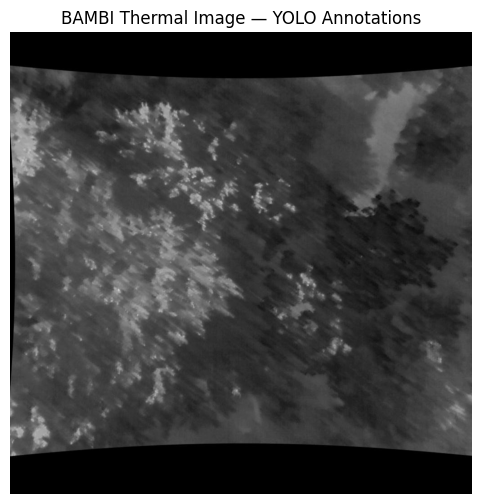

In [7]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path("/content/thermal_data/bambi")
images = sorted((dataset / "train/images").glob("*"))
images = [p for p in images if p.suffix.lower() in
          [".jpg", ".jpeg", ".png"]]

img_path = images[0]
label_path = dataset / "train/labels" / (img_path.stem + ".txt")

img = cv2.imread(str(img_path))
if img is None:
    raise ValueError("Unable to read sample image")

h, w = img.shape[:2]
boxes = []

if label_path.exists():
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls, x, y, bw, bh = map(float, parts)
        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)
        boxes.append((int(cls), x1, y1, x2, y2))
        cv2.rectangle(img, (x1, y1), (x2, y2),
                      (0, 255, 0), 2)

print("Image:", img_path.name)
print("Image dimensions:", w, "x", h)
print("Annotations:", len(boxes))
print("Bounding boxes:", boxes[:5])

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("BAMBI Thermal Image — YOLO Annotations")
plt.show()


Image: 0_8083_jpg.rf.09e7a85491cdce4ffd720430fa111d51.jpg
Number of annotations: 1


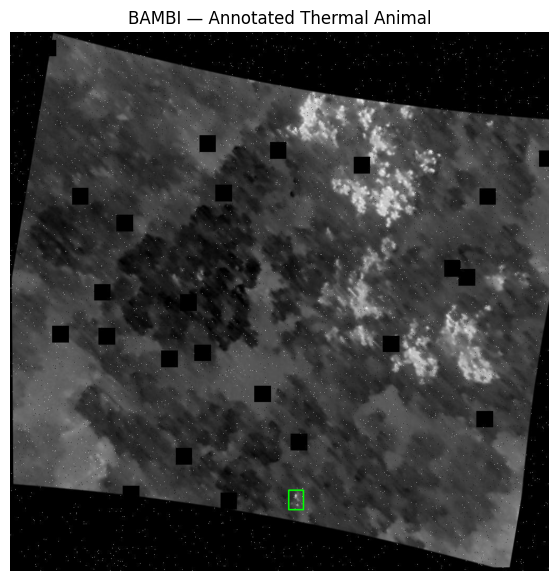

In [8]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path("/content/thermal_data/bambi")

image_dir = dataset / "train/images"
label_dir = dataset / "train/labels"

found = False

for label_path in sorted(label_dir.glob("*.txt")):
    lines = label_path.read_text().strip().splitlines()

    if not lines:
        continue

    for ext in [".jpg", ".jpeg", ".png"]:
        img_path = image_dir / (label_path.stem + ext)
        if img_path.exists():
            found = True
            break

    if found:
        break

if not found:
    raise ValueError("No labeled animal images found!")

img = cv2.imread(str(img_path))
h, w = img.shape[:2]

for line in lines:
    values = line.split()

    if len(values) != 5:
        continue

    cls, x, y, bw, bh = map(float, values)

    x1 = int((x - bw / 2) * w)
    y1 = int((y - bh / 2) * h)
    x2 = int((x + bw / 2) * w)
    y2 = int((y + bh / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2),
                  (0, 255, 0), 2)

print("Image:", img_path.name)
print("Number of annotations:", len(lines))

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("BAMBI — Annotated Thermal Animal")
plt.axis("off")
plt.show()


In [9]:

from pathlib import Path
from collections import Counter

base = Path("/content/thermal_data/bambi")

for split in ["train", "valid", "test"]:
    labels = list((base / split / "labels").glob("*.txt"))

    positive = 0
    empty = 0
    invalid = 0
    total_boxes = 0

    for file in labels:
        lines = file.read_text().strip().splitlines()

        if not lines:
            empty += 1
            continue

        positive += 1

        for line in lines:
            try:
                values = list(map(float, line.split()))
                if len(values) != 5:
                    invalid += 1
                    continue

                cls, x, y, w, h = values

                if not (
                    cls == 0 and
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1 and
                    x - w/2 >= -1e-5 and
                    y - h/2 >= -1e-5 and
                    x + w/2 <= 1 + 1e-5 and
                    y + h/2 <= 1 + 1e-5
                ):
                    invalid += 1

                total_boxes += 1

            except ValueError:
                invalid += 1

    print(f"\n{split.upper()}")
    print("Positive images:", positive)
    print("Empty images:", empty)
    print("Total boxes:", total_boxes)
    print("Invalid annotations:", invalid)



TRAIN
Positive images: 72707
Empty images: 5943
Total boxes: 221063
Invalid annotations: 0

VALID
Positive images: 1447
Empty images: 249
Total boxes: 9823
Invalid annotations: 0

TEST
Positive images: 1515
Empty images: 311
Total boxes: 4926
Invalid annotations: 0


In [10]:

%pip install -q ultralytics

from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

print("Model: YOLO11n")
print("GPU:", torch.cuda.get_device_name(0))
print("Number of detection classes:", len(model.names))
print("Model loaded successfully!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 9.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model: YOLO11n
GPU: Tesla T4
Number of detection classes: 80
Model loaded successfully!


In [11]:

from pathlib import Path
import yaml

base = Path("/content/thermal_data/bambi")

config = {
    "path": str(base),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": {0: "animal"}
}

config_path = base / "ghostvision_thermal.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("GhostVision thermal configuration created!")
print("Configuration path:", config_path)
print()
print(config_path.read_text())

for split in ["train", "valid", "test"]:
    assert (base / split / "images").is_dir()
    assert (base / split / "labels").is_dir()

print("All dataset folders verified!")


GhostVision thermal configuration created!
Configuration path: /content/thermal_data/bambi/ghostvision_thermal.yaml

path: /content/thermal_data/bambi
train: train/images
val: valid/images
test: test/images
nc: 1
names:
  0: animal

All dataset folders verified!


In [12]:

from pathlib import Path
from collections import defaultdict
import hashlib

base = Path("/content/thermal_data/bambi")
hashes = defaultdict(set)
counts = {"train": 0, "valid": 0, "test": 0}

for split in ["train", "valid", "test"]:
    folder = base / split / "images"

    for file in folder.iterdir():
        if file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        h = hashlib.sha256()

        with open(file, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)

        hashes[split].add(h.hexdigest())
        counts[split] += 1

    print(f"{split}: {counts[split]} images hashed")

print("\nEXACT DUPLICATES BETWEEN SPLITS")

for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = len(hashes[a] & hashes[b])
    print(f"{a} vs {b}: {overlap}")


train: 78650 images hashed
valid: 1696 images hashed
test: 1826 images hashed

EXACT DUPLICATES BETWEEN SPLITS
train vs valid: 0
train vs test: 0
valid vs test: 0


In [13]:

from pathlib import Path
import random
import shutil
import yaml

source = Path("/content/thermal_data/bambi")
pilot = Path("/content/thermal_data/pilot")
rng = random.Random(42)

def prepare_split(split, amount):
    src_images = source / split / "images"
    src_labels = source / split / "labels"

    dst_images = pilot / split / "images"
    dst_labels = pilot / split / "labels"

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    positive = []
    negative = []

    for img in src_images.iterdir():
        if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        label = src_labels / (img.stem + ".txt")

        if not label.exists():
            continue

        if label.stat().st_size > 0:
            positive.append(img)
        else:
            negative.append(img)

    rng.shuffle(positive)
    rng.shuffle(negative)

    n_negative = min(round(amount * 0.15), len(negative))
    selected = positive[:amount - n_negative]
    selected += negative[:n_negative]
    rng.shuffle(selected)

    for img in selected:
        shutil.copy2(img, dst_images / img.name)
        label = src_labels / (img.stem + ".txt")
        shutil.copy2(label, dst_labels / label.name)

    print(split, ":", len(selected), "images",
          "| positive:", len(selected) - n_negative,
          "| negative:", n_negative)

prepare_split("train", 2000)
prepare_split("valid", 300)

pilot_config = {
    "path": str(pilot),
    "train": "train/images",
    "val": "valid/images",
    "nc": 1,
    "names": {0: "animal"}
}

with open(pilot / "data.yaml", "w") as f:
    yaml.safe_dump(pilot_config, f, sort_keys=False)

print("\nPilot dataset prepared!")
print("Configuration:", pilot / "data.yaml")


train : 2000 images | positive: 1700 | negative: 300
valid : 300 images | positive: 255 | negative: 45

Pilot dataset prepared!
Configuration: /content/thermal_data/pilot/data.yaml


In [14]:

from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "GPU not connected!"

# Load pretrained YOLO11n
model = YOLO("yolo11n.pt")

# Train on the BAMBI thermal pilot dataset
results = model.train(
    data="/content/thermal_data/pilot/data.yaml",
    epochs=3,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/thermal_runs",
    name="yolo11n_pilot_v1",
    seed=42,
    plots=True
)

print("Pilot training completed!")
print("Results saved in:", model.trainer.save_dir)


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thermal_data/pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_pilot_v1, nbs=64, nms=None, opset=None, optim

In [15]:

from google.colab import drive
from pathlib import Path
import shutil
import hashlib
import json

drive.mount("/content/drive")

source = Path(
    "/content/thermal_runs/yolo11n_pilot_v1"
)

backup = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1"
)

backup.mkdir(parents=True, exist_ok=True)

files = [
    "weights/best.pt",
    "weights/last.pt",
    "results.csv",
    "args.yaml"
]

for filename in files:
    src = source / filename
    dst = backup / filename

    if not src.exists():
        print("Missing:", filename)
        continue

    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    def checksum(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(
                lambda: f.read(1024 * 1024),
                b""
            ):
                h.update(chunk)
        return h.hexdigest()

    assert checksum(src) == checksum(dst)
    print("Verified backup:", filename)

print("\nModel backup location:", backup)
print("Backup complete!")


Mounted at /content/drive
Verified backup: weights/best.pt
Verified backup: weights/last.pt
Verified backup: results.csv
Verified backup: args.yaml

Model backup location: /content/drive/MyDrive/GhostVision-AI/thermal/yolo11n_pilot_v1
Backup complete!


Image: 147_10075_jpg.rf.7430b3c9873b9dde91c90f73a7cad9de.jpg
Animals detected: 4
Class: animal | Confidence: 0.824
Class: animal | Confidence: 0.724
Class: animal | Confidence: 0.539
Class: animal | Confidence: 0.407


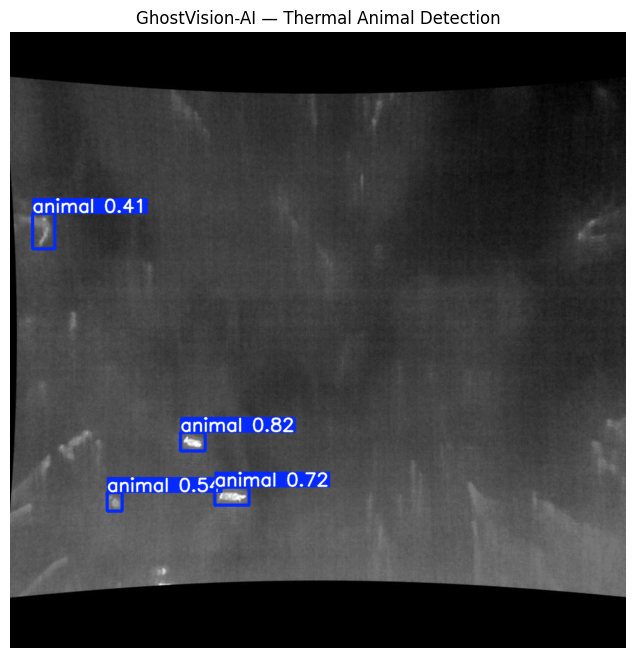

In [16]:

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import random

# Load trained thermal model from Google Drive
model_path = (
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1/weights/best.pt"
)

model = YOLO(model_path)

# Select a reproducible validation image
images = sorted(
    Path("/content/thermal_data/pilot/valid/images").glob("*.jpg")
)

assert images, "No validation images found"

rng = random.Random(42)
image_path = rng.choice(images)

# Predict animal locations
results = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

result = results[0]

print("Image:", image_path.name)
print("Animals detected:", len(result.boxes))

for box in result.boxes:
    print(
        "Class:", model.names[int(box.cls.item())],
        "| Confidence:", round(box.conf.item(), 3)
    )

# Display image with bounding boxes
annotated = result.plot()

plt.figure(figsize=(10, 8))
plt.imshow(annotated[:, :, ::-1])
plt.title("GhostVision-AI — Thermal Animal Detection")
plt.axis("off")
plt.show()


Ground-truth animals: 4
Predicted animals: 4


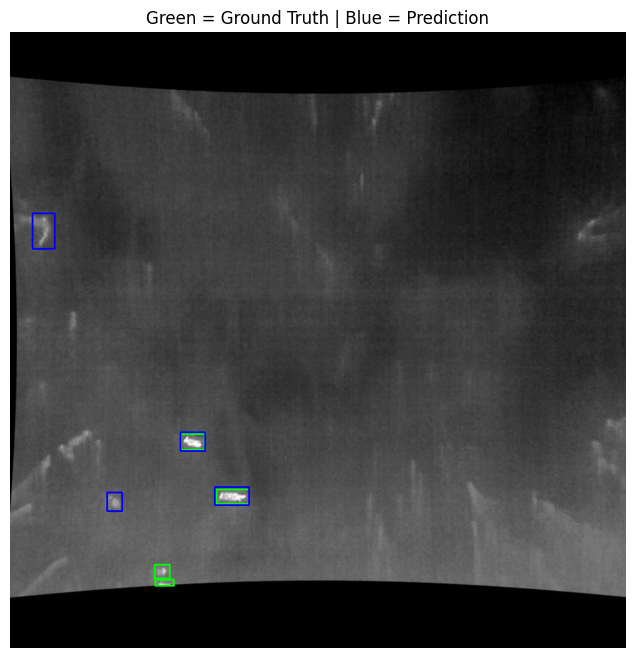

In [17]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

# Use the same image from Step 15
image_path = Path(
    "/content/thermal_data/pilot/valid/images/"
    "147_10075_jpg.rf.7430b3c9873b9dde91c90f73a7cad9de.jpg"
)

model_path = (
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1/weights/best.pt"
)

model = YOLO(model_path)
img = cv2.imread(str(image_path))

assert img is not None, "Image not found"

height, width = img.shape[:2]

# Ground-truth bounding boxes (green)
label_path = (
    Path("/content/thermal_data/pilot/valid/labels")
    / (image_path.stem + ".txt")
)

gt_count = 0

for line in label_path.read_text().splitlines():
    cls, x, y, w, h = map(float, line.split())

    x1 = int((x - w / 2) * width)
    y1 = int((y - h / 2) * height)
    x2 = int((x + w / 2) * width)
    y2 = int((y + h / 2) * height)

    cv2.rectangle(
        img, (x1, y1), (x2, y2),
        (0, 255, 0), 2
    )
    gt_count += 1

# Model predictions (blue)
results = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

pred_count = 0

for box in results[0].boxes:
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].tolist()
    )

    cv2.rectangle(
        img, (x1, y1), (x2, y2),
        (255, 0, 0), 2
    )
    pred_count += 1

print("Ground-truth animals:", gt_count)
print("Predicted animals:", pred_count)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(
    "Green = Ground Truth | Blue = Prediction"
)
plt.axis("off")
plt.show()


In [18]:

import numpy as np
from scipy.optimize import linear_sum_assignment

# YOLO model predictions
pred_boxes = results[0].boxes.xyxy.cpu().numpy()

# Read ground-truth YOLO labels
gt_boxes = []

for line in label_path.read_text().splitlines():
    cls, x, y, bw, bh = map(float, line.split())

    gt_boxes.append([
        (x - bw/2) * width,
        (y - bh/2) * height,
        (x + bw/2) * width,
        (y + bh/2) * height
    ])

gt_boxes = np.array(gt_boxes).reshape(-1, 4)

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    return intersection / (area1 + area2 - intersection + 1e-9)

iou_matrix = np.array([
    [calculate_iou(p, g) for g in gt_boxes]
    for p in pred_boxes
]).reshape(len(pred_boxes), len(gt_boxes))

# Match prediction and GT boxes at IoU >= 0.5
threshold = 0.5

if iou_matrix.size:
    rows, cols = linear_sum_assignment(-iou_matrix)

    matches = [
        (r, c, iou_matrix[r, c])
        for r, c in zip(rows, cols)
        if iou_matrix[r, c] >= threshold
    ]
else:
    matches = []

tp = len(matches)
fp = len(pred_boxes) - tp
fn = len(gt_boxes) - tp

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))

for r, c, iou in matches:
    print(f"Prediction {r+1} → GT {c+1}: IoU={iou:.3f}")


True Positives: 2
False Positives: 2
False Negatives: 2
Precision: 0.5
Recall: 0.5
Prediction 1 → GT 1: IoU=0.818
Prediction 2 → GT 2: IoU=0.754


In [19]:

from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1/weights/best.pt"
)

metrics = model.val(
    data="/content/thermal_data/pilot/data.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/thermal_runs",
    name="pilot_validation_check"
)

print("\nPILOT VALIDATION RESULTS")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1163.0±413.1 MB/s, size: 62.6 KB)
val: Scanning /content/thermal_data/pilot/valid/labels.cache... 300 images, 45 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 66.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 5.9it/s 6.5s
                   all        300       1867      0.765      0.735      0.821      0.507
Speed: 1.8ms preprocess, 7.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/thermal_runs/pilot_validation_check

PILOT VALIDATION RESULTS
Precision: 0.765
Recall: 0.7354
mAP50: 0.8212
mAP50-95: 0.5065


In [20]:

from pathlib import Path
from collections import Counter

base = Path("/content/thermal_data/bambi")

for split in ["train", "valid", "test"]:
    images = sorted(
        p for p in (base / split / "images").iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    # Strip Roboflow augmentation/hash suffix
    original_ids = [
        p.name.split("_jpg.rf.")[0]
        for p in images
    ]

    # Tentative recording prefix — not yet verified
    prefixes = [
        name.split("_")[0]
        for name in original_ids
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Unique original IDs:", len(set(original_ids)))
    print("Unique prefixes:", len(set(prefixes)))
    print("Example filenames:", [p.name for p in images[:3]])
    print("Top prefixes:", Counter(prefixes).most_common(5))



TRAIN
Images: 78650
Unique original IDs: 15730
Unique prefixes: 160
Example filenames: ['0_7707_jpg.rf.a782601dee3a5cec889f4696784c8c73.jpg', '0_7707_jpg.rf.a8356534726e36ef3d36ac85d20deb2a.jpg', '0_7707_jpg.rf.afa2deb90ea954429024b36dfbfe5bd2.jpg']
Top prefixes: [('31', 2460), ('28', 1885), ('86', 1740), ('41', 1730), ('142', 1550)]

VALID
Images: 1696
Unique original IDs: 1696
Unique prefixes: 28
Example filenames: ['10_1980_jpg.rf.90e20db6e3da8c5b2b00124e4a77ffaa.jpg', '10_2338_jpg.rf.d25ad23e6da6c9c5cdb84432d1b7eec2.jpg', '10_2354_jpg.rf.6cd70630ff18f2bddbfa2b50f752ec27.jpg']
Top prefixes: [('6', 167), ('10', 120), ('176', 118), ('57', 116), ('13', 110)]

TEST
Images: 1826
Unique original IDs: 1826
Unique prefixes: 35
Example filenames: ['152_14393_jpg.rf.333118b6328ba61effb9855b060da05c.jpg', '152_14533_jpg.rf.2c5305ca86b4c54f790c585ed5ad19b0.jpg', '152_14633_jpg.rf.a3ff42d838bf189f9e888d94b67fb6d3.jpg']
Top prefixes: [('284', 200), ('276', 198), ('282', 143), ('283', 133), ('277

In [21]:

from pathlib import Path

base = Path("/content/thermal_data/bambi")

original_ids = {}
prefixes = {}

for split in ["train", "valid", "test"]:
    image_dir = base / split / "images"

    ids = set()
    groups = set()

    for file in image_dir.iterdir():
        if file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        original = file.name.split("_jpg.rf.")[0]
        prefix = original.split("_")[0]

        ids.add(original)
        groups.add(prefix)

    original_ids[split] = ids
    prefixes[split] = groups

print("ORIGINAL IMAGE ID OVERLAP")

for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = original_ids[a] & original_ids[b]
    print(f"{a} vs {b}: {len(overlap)}")

print("\nPREFIX OVERLAP")

for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = prefixes[a] & prefixes[b]
    print(f"{a} vs {b}: {len(overlap)}")
    print("Shared prefixes:", sorted(overlap))


ORIGINAL IMAGE ID OVERLAP
train vs valid: 0
train vs test: 0
valid vs test: 0

PREFIX OVERLAP
train vs valid: 0
Shared prefixes: []
train vs test: 0
Shared prefixes: []
valid vs test: 0
Shared prefixes: []


In [22]:

from pathlib import Path
import shutil
import torch

dataset = Path("/content/thermal_data/bambi")
checkpoint = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1/weights/best.pt"
)

print("FULL TRAINING READINESS CHECK")
print("-----------------------------")

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1e9,
            2
        ),
        "GB"
    )

print(
    "Free disk space:",
    round(shutil.disk_usage("/content").free / 1e9, 2),
    "GB"
)

print("Dataset exists:", dataset.exists())
print(
    "Dataset configuration:",
    (dataset / "ghostvision_thermal.yaml").exists()
)
print("Pilot checkpoint exists:", checkpoint.exists())

for split in ["train", "valid", "test"]:
    folder = dataset / split / "images"

    count = sum(
        1 for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ) if folder.exists() else 0

    print(f"{split} images:", count)


FULL TRAINING READINESS CHECK
-----------------------------
GPU available: True
GPU: Tesla T4
GPU memory: 15.64 GB
Free disk space: 55.76 GB
Dataset exists: True
Dataset configuration: True
Pilot checkpoint exists: True
train images: 78650
valid images: 1696
test images: 1826


In [23]:

from pathlib import Path
from collections import defaultdict
import random
import shutil
import yaml

source = Path("/content/thermal_data/bambi")
target = Path("/content/thermal_data/large_pilot_v1")

groups = defaultdict(list)

for img in (source / "train/images").iterdir():
    if img.suffix.lower() not in (".jpg", ".jpeg", ".png"):
        continue

    original_id = img.name.split("_jpg.rf.")[0]
    groups[original_id].append(img)

rng = random.Random(42)
selected_ids = rng.sample(sorted(groups), 2000)

train_images = target / "train/images"
train_labels = target / "train/labels"
train_images.mkdir(parents=True, exist_ok=True)
train_labels.mkdir(parents=True, exist_ok=True)

count = 0

for original_id in selected_ids:
    for img in groups[original_id]:
        label = source / "train/labels" / (img.stem + ".txt")

        if not label.exists():
            raise FileNotFoundError(label)

        shutil.copy2(img, train_images / img.name)
        shutil.copy2(label, train_labels / label.name)
        count += 1

# Use the entire existing validation split directly.
# Do not copy or modify validation/test images.
config = {
    "path": str(target),
    "train": "train/images",
    "val": str(source / "valid/images"),
    "nc": 1,
    "names": {0: "animal"}
}

config_path = target / "data.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Selected original IDs:", len(selected_ids))
print("Training images copied:", count)
print("Full validation images:", len(list(
    (source / "valid/images").glob("*.jpg")
)))
print("Configuration:", config_path)

assert count == 10000, "Unexpected augmentation count!"
print("Larger experiment dataset prepared!")


Selected original IDs: 2000
Training images copied: 10000
Full validation images: 1696
Configuration: /content/thermal_data/large_pilot_v1/data.yaml
Larger experiment dataset prepared!


In [24]:

from ultralytics import YOLO
from pathlib import Path
import torch

assert torch.cuda.is_available(), "GPU not connected!"

data_path = Path(
    "/content/thermal_data/large_pilot_v1/data.yaml"
)

assert data_path.exists(), "Dataset YAML missing!"

# Load original pretrained model
model = YOLO("yolo11n.pt")

# Start larger thermal training experiment
results = model.train(
    data=str(data_path),
    epochs=15,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    seed=42,
    patience=10,
    save=True,
    save_period=5,
    project="/content/thermal_runs",
    name="yolo11n_large_v1",
    plots=True
)

print("\nLARGER TRAINING COMPLETED")
print("Results:", model.trainer.save_dir)


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thermal_data/large_pilot_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_large_v1, nbs=64, nms=None, opset=N

In [25]:

from pathlib import Path
import shutil
import hashlib

source = Path("/content/thermal_runs/yolo11n_large_v1")

backup = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1"
)

# Mount Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

backup.mkdir(parents=True, exist_ok=True)

files = [
    "weights/best.pt",
    "weights/last.pt",
    "results.csv",
    "args.yaml"
]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

for filename in files:
    src = source / filename
    dst = backup / filename

    if not src.exists():
        raise FileNotFoundError(src)

    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    assert sha256(src) == sha256(dst)
    print("Verified backup:", filename)

print("\nAll files backed up successfully!")
print("Backup location:", backup)


Verified backup: weights/best.pt
Verified backup: weights/last.pt
Verified backup: results.csv
Verified backup: args.yaml

All files backed up successfully!
Backup location: /content/drive/MyDrive/GhostVision-AI/thermal/yolo11n_large_v1


In [26]:

from ultralytics import YOLO
from pathlib import Path
import json

model_path = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1/weights/best.pt"
)

data_path = Path(
    "/content/thermal_data/bambi/ghostvision_thermal.yaml"
)

assert model_path.exists(), "Model checkpoint missing!"
assert data_path.exists(), "Dataset configuration missing!"

model = YOLO(str(model_path))

metrics = model.val(
    data=str(data_path),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    plots=True,
    project="/content/thermal_runs",
    name="yolo11n_large_v1_test"
)

results = {
    "model": "YOLO11n",
    "dataset": "BAMBI",
    "split": "test",
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "map50": float(metrics.box.map50),
    "map50_95": float(metrics.box.map)
}

print("\nFINAL TEST RESULTS")
print("------------------------------")
print("Precision:", round(results["precision"], 4))
print("Recall:", round(results["recall"], 4))
print("mAP50:", round(results["map50"], 4))
print("mAP50-95:", round(results["map50_95"], 4))

# Save actual test metrics to Google Drive
output = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1/test_metrics.json"
)

output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(json.dumps(results, indent=2))

print("\nTest metrics saved:", output)


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 24.3±17.2 MB/s, size: 108.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/thermal_data/bambi/test/labels... 1826 images, 311 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1826/1826 503.7it/s 3.6s
val: New cache created: /content/thermal_data/bambi/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 229/229 9.9it/s 23.2s
                   all       1826       4926      0.909      0.893      0.958      0.723
Speed: 1.5ms preprocess, 5.1ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/thermal_runs/yolo11n_large_v1_test

FINAL TEST RESULTS
---

In [27]:

from pathlib import Path
import shutil

source = Path(
    "/content/thermal_runs/yolo11n_large_v1_test"
)

backup = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1/test_evidence"
)

backup.mkdir(parents=True, exist_ok=True)

count = 0

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "P_curve.png",
    "R_curve.png",
    "F1_curve.png"
]:
    src = source / filename

    if src.exists():
        shutil.copy2(src, backup / filename)
        print("Saved:", filename)
        count += 1
    else:
        print("Not generated:", filename)

print("\nEvaluation plots saved:", count)
print("Location:", backup)


Saved: confusion_matrix.png
Saved: confusion_matrix_normalized.png
Not generated: PR_curve.png
Not generated: P_curve.png
Not generated: R_curve.png
Not generated: F1_curve.png

Evaluation plots saved: 2
Location: /content/drive/MyDrive/GhostVision-AI/thermal/yolo11n_large_v1/test_evidence


Thermal test image:


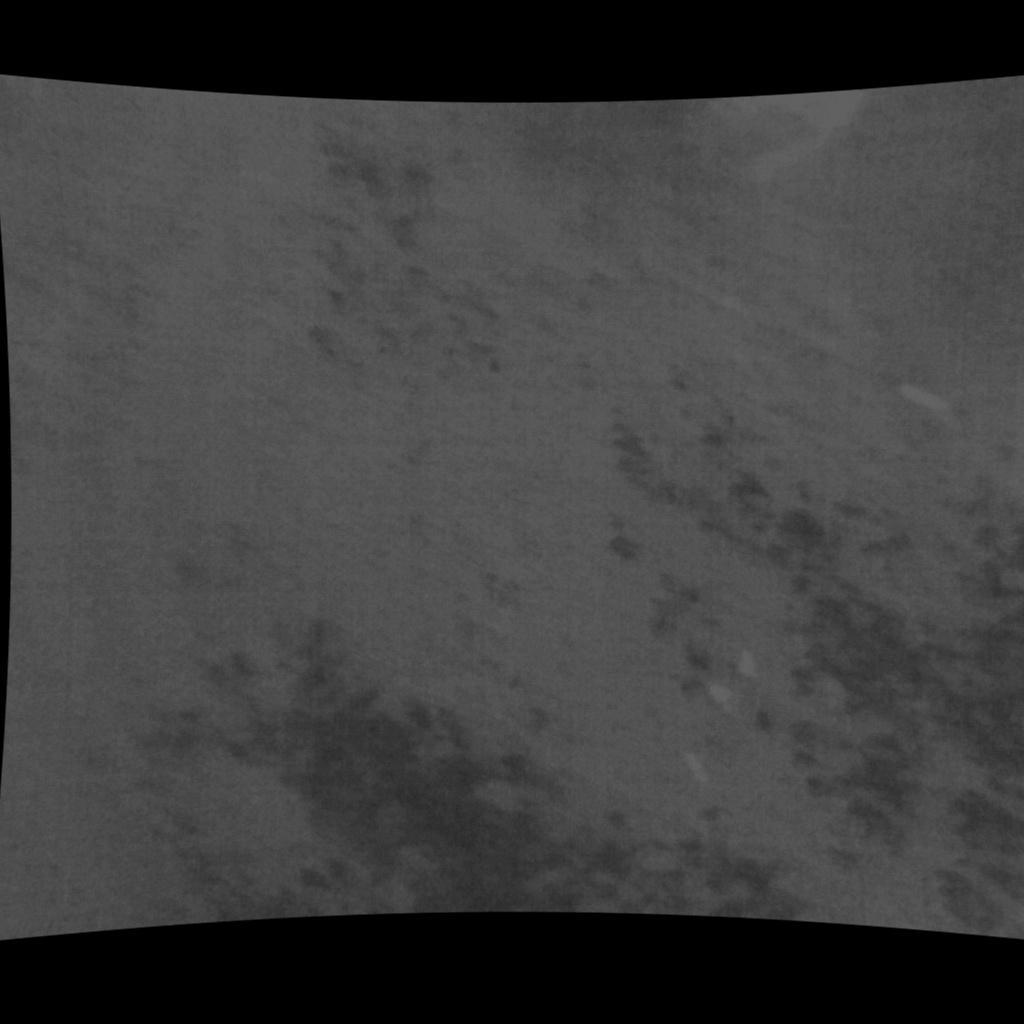

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

from pathlib import Path
from google.colab import files
from PIL import Image
from IPython.display import display
import shutil

test_dir = Path("/content/thermal_data/bambi/test")

# Find a test image containing annotated animals
for label in sorted((test_dir / "labels").glob("*.txt")):
    lines = label.read_text().strip().splitlines()

    if len(lines) >= 2:
        image_path = test_dir / "images" / (label.stem + ".jpg")

        if image_path.exists():
            break
else:
    raise FileNotFoundError("No suitable thermal image found")

# Save without detection boxes
output = Path("/content/ghostvision_thermal_test.jpg")
shutil.copy2(image_path, output)

print("Thermal test image:")
display(Image.open(output))

# Download image to your computer
files.download(str(output))


GhostVision-AI Thermal Detection
Upload a thermal wildlife image


Saving ghostvision_thermal_test.jpg to ghostvision_thermal_test.jpg

Image: ghostvision_thermal_test.jpg
Animals detected: 0


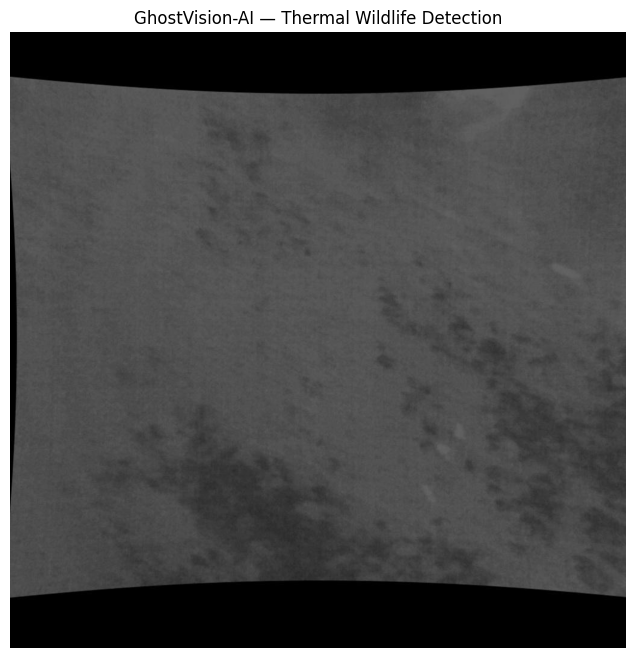

In [30]:

from google.colab import files
from ultralytics import YOLO
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import io

# Load our trained thermal model
model_path = (
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1/weights/best.pt"
)

model = YOLO(model_path)

print("GhostVision-AI Thermal Detection")
print("Upload a thermal wildlife image")

uploaded = files.upload()

for filename, image_bytes in uploaded.items():
    image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

    results = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )

    result = results[0]

    print("\nImage:", filename)
    print("Animals detected:", len(result.boxes))

    for i, box in enumerate(result.boxes, 1):
        print(
            f"Animal {i}: "
            f"{box.conf.item() * 100:.1f}% confidence"
        )

    annotated = result.plot(pil=True)

    plt.figure(figsize=(11, 8))
    plt.imshow(annotated)
    plt.title("GhostVision-AI — Thermal Wildlife Detection")
    plt.axis("off")
    plt.show()


Predictions at confidence 0.05: 2
Confidence: 0.1994
Confidence: 0.0943


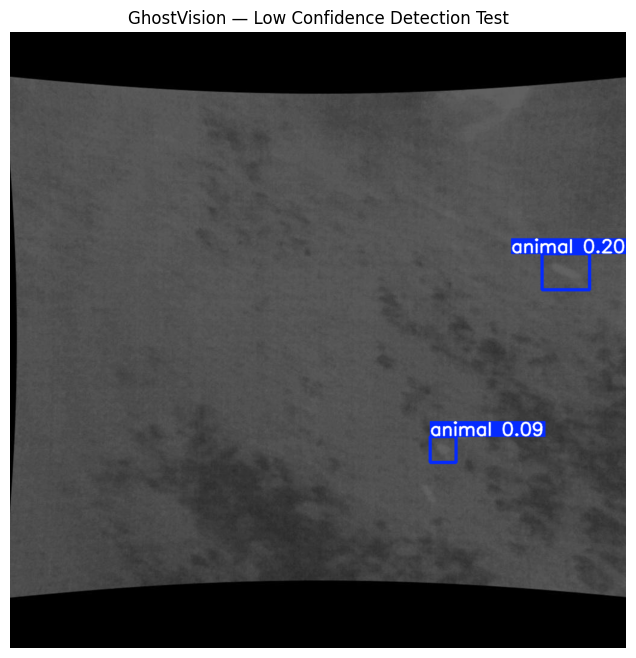

In [31]:

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

model = YOLO(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_large_v1/weights/best.pt"
)

image_path = Path(
    "/content/ghostvision_thermal_test.jpg"
)

# Test a lower confidence threshold
results = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.05,
    device=0,
    verbose=False
)

result = results[0]

print("Predictions at confidence 0.05:",
      len(result.boxes))

for box in result.boxes:
    print("Confidence:", round(box.conf.item(), 4))

annotated = result.plot()

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("GhostVision — Low Confidence Detection Test")
plt.axis("off")
plt.show()


Ground-truth animals: 3
Predicted candidates: 2


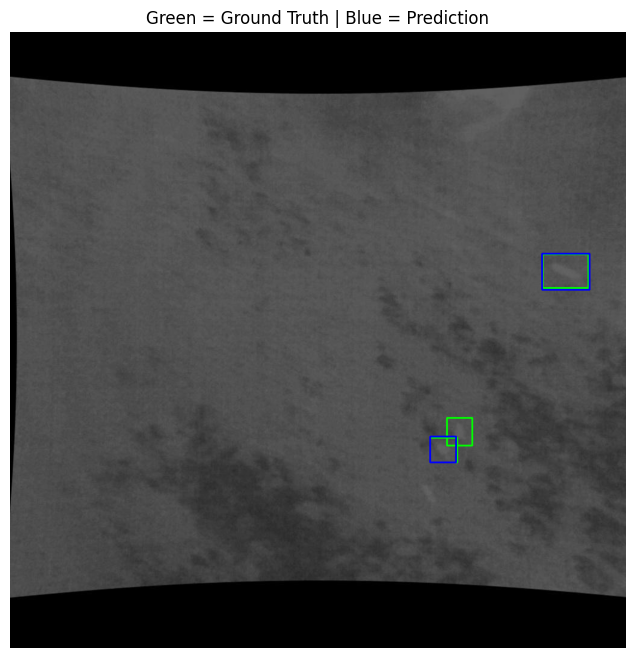

In [32]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Original test image selected earlier
image_path = Path(
    "/content/ghostvision_thermal_test.jpg"
)

# Find its original YOLO annotation
test_dir = Path("/content/thermal_data/bambi/test")
original_name = None

# Compare file contents to locate the source image
import hashlib

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.digest()

target_hash = file_hash(image_path)

for candidate in (test_dir / "images").glob("*.jpg"):
    if file_hash(candidate) == target_hash:
        original_name = candidate.stem
        break

assert original_name is not None, "Original test image not found"

label_path = test_dir / "labels" / f"{original_name}.txt"

img = cv2.imread(str(image_path))
height, width = img.shape[:2]

gt_count = 0

# Draw ground truth in green
for line in label_path.read_text().splitlines():
    cls, x, y, bw, bh = map(float, line.split())

    x1 = int((x - bw / 2) * width)
    y1 = int((y - bh / 2) * height)
    x2 = int((x + bw / 2) * width)
    y2 = int((y + bh / 2) * height)

    cv2.rectangle(img, (x1, y1), (x2, y2),
                  (0, 255, 0), 2)
    gt_count += 1

# Draw existing low-confidence predictions in blue
for box in results[0].boxes:
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].tolist()
    )
    cv2.rectangle(img, (x1, y1), (x2, y2),
                  (255, 0, 0), 2)

print("Ground-truth animals:", gt_count)
print("Predicted candidates:", len(results[0].boxes))

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Green = Ground Truth | Blue = Prediction")
plt.axis("off")
plt.show()
